In [1]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

print("Kernel is working")
print(np.__version__)

Kernel is working
2.5.3


Classical DSP Refresher
Frequency Response $H(f)$ and Pure Time Delay

Time Shift Property: A pure time delay $t_0$ transforms in the frequency domain into a linear phase multiplier:$$\mathcal{F}\{x(t - t_0)\} = X(f) e^{-j 2\pi f t_0}$$

Where the shift lives: The time shift appears as a complex exponential multiplying on the outside, directly modifying the phase angle while preserving the magnitude:$$\vert{}e^{-j 2\pi f t_0}\vert{} = 1, \quad \angle e^{-j 2\pi f t_0} = -2\pi f t_0$$

LTI Filter Response: If an LTI filter simply delays an input by $t_0$ without distorting the amplitude, its frequency response is:$$H(f) = e^{-j 2\pi f t_0}$$

The magnitude of the delay response does not decrease with frequency: $|H(f)|=1$. The phase decreases linearly with frequency because a fixed time delay corresponds to a larger fraction of a cycle at higher frequencies.
For example, with t0=.15s,
at f=1Hz, delay is .15 cycles or -0.3pi radians
at f=10Hz, delay is 1.5 cycles or -3pi radians

The delay remains exactly 0.15 seconds in every case. The phase shift grows because higher-frequency waves complete more cycles during those same 0.15 seconds.


So when there is a delay of .15 seconds, 
t0 = .15, 
The output = 
Y(f)=X(f)H(f)=X(f)e^(−j2πft0)
Y(f)=X(f)H(f)=X(f)e^(−j2πf(.15))

In the graph below, the input is a sine wave with f0 = 3 Hz and phase phi = pi/4:
x(t)=A sin(2 pi f0 t + phi)

The FFT of the sampled input estimates X(f). Because the sine wave is real-valued, its spectrum has matching positive- and negative-frequency components at f=+f0 and f=-f0. A cosine would have the same frequency locations but different complex phases.

The output spectrum is
Y(f)=X(f)e^(−j2πf(.15))

In the time domain, the same relationship is
y(t)=x(t-0.15)

The graph compares x(t) and y(t), their FFT magnitudes, and the pure-delay response H(f).

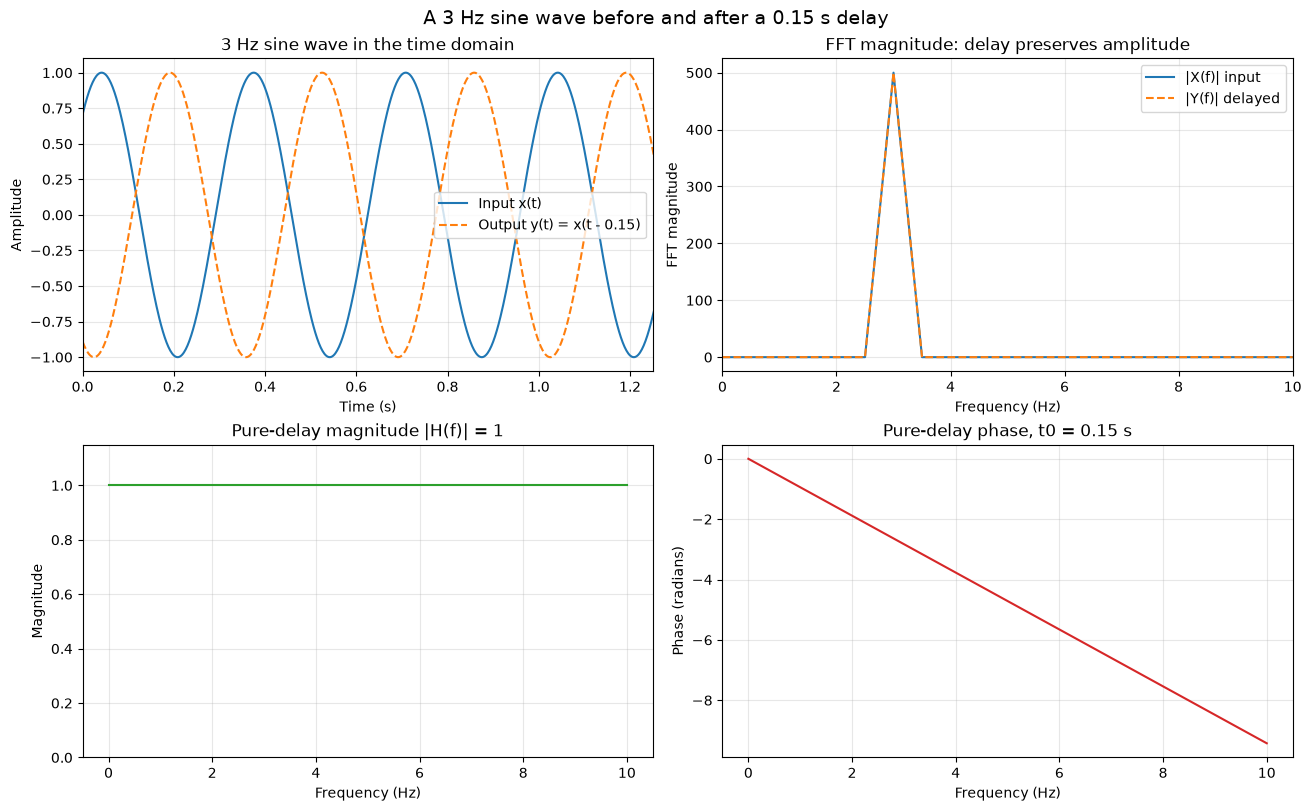

In [3]:
# Wave properties: amplitude, frequency, phase, and time delay
sample_rate = 500  # samples per second
observation_time = 2.0
time = np.arange(0, observation_time, 1 / sample_rate)

amplitude = 1.0
frequency = 3.0  # Hz
phase = np.pi / 4
delay = 0.15  # seconds

# Input sine wave and its delayed output.
signal = amplitude * np.sin(2 * np.pi * frequency * time + phase)
delayed_signal = amplitude * np.sin(
    2 * np.pi * frequency * (time - delay) + phase
)

# Frequency response of the pure delay: H(f) = exp(-j 2 pi f t0).
frequencies = np.linspace(0, 10, 400)
delay_response = np.exp(-1j * 2 * np.pi * frequencies * delay)

# One-sided FFTs estimate X(f) and Y(f) from the sampled signals.
fft_frequencies = np.fft.rfftfreq(time.size, d=1 / sample_rate)
input_spectrum = np.fft.rfft(signal)
output_spectrum = np.fft.rfft(delayed_signal)
spectrum_limit = fft_frequencies <= 10

figure, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)

# The delay shifts the wave in time without changing its amplitude or frequency.
axes[0, 0].plot(time, signal, color="tab:blue", label="Input x(t)")
axes[0, 0].plot(time, delayed_signal, color="tab:orange", linestyle="--", label="Output y(t) = x(t - 0.15)")
axes[0, 0].set_title("3 Hz sine wave in the time domain")
axes[0, 0].set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Amplitude")
axes[0, 0].set_xlim(0, 1.25)
axes[0, 0].grid(alpha=0.3)
axes[0, 0].legend()

# A pure delay preserves the FFT magnitude: |Y(f)| = |X(f)|.
axes[0, 1].plot(fft_frequencies[spectrum_limit], np.abs(input_spectrum[spectrum_limit]), color="tab:blue", label="|X(f)| input")
axes[0, 1].plot(fft_frequencies[spectrum_limit], np.abs(output_spectrum[spectrum_limit]), color="tab:orange", linestyle="--", label="|Y(f)| delayed")
axes[0, 1].set_title("FFT magnitude: delay preserves amplitude")
axes[0, 1].set_xlabel("Frequency (Hz)")
axes[0, 1].set_ylabel("FFT magnitude")
axes[0, 1].set_xlim(0, 10)
axes[0, 1].grid(alpha=0.3)
axes[0, 1].legend()

# The magnitude of H(f) is one at every frequency.
axes[1, 0].plot(frequencies, np.abs(delay_response), color="tab:green")
axes[1, 0].set_title("Pure-delay magnitude |H(f)| = 1")
axes[1, 0].set_xlabel("Frequency (Hz)")
axes[1, 0].set_ylabel("Magnitude")
axes[1, 0].set_ylim(0, 1.15)
axes[1, 0].grid(alpha=0.3)

# The phase decreases linearly with frequency: angle H(f) = -2 pi f t0.
axes[1, 1].plot(frequencies, np.unwrap(np.angle(delay_response)), color="tab:red")
axes[1, 1].set_title(f"Pure-delay phase, t0 = {delay:g} s")
axes[1, 1].set_xlabel("Frequency (Hz)")
axes[1, 1].set_ylabel("Phase (radians)")
axes[1, 1].grid(alpha=0.3)

figure.suptitle("A 3 Hz sine wave before and after a 0.15 s delay", fontsize=14)
plt.show()



1. Time-Invariance
A system $\mathcal{T}$ is Time-Invariant if a delay in the input signal produces the exact same delay in the output:
$$\mathcal{T}\{x(t - t_0)\} = y(t - t_0) \quad \text{where } y(t) = \mathcal{T}\{x(t)\}$$

The system’s internal physical properties do not age or change over time. An interrogator measuring acoustic wave speed down a fiber cable is time-invariant if identical pulses launched at 08:00 and 14:00 produce identical optical phase responses.

2. Causality
A system is Causal if the output at the current time $t$ depends only on present and past inputs ($x(\tau)$ for $\tau \le t$), never on future values ($x(\tau)$ for $\tau > t$):$$h(t) = 0 \quad \text{for } t < 0$$:
$$h(t) = 0 \quad \text{for } t < 0$$

Real-time vs. Post-processing: Physical real-time DAS interrogators are strictly causal. However, during post-processing in a Jupyter notebook, zero-phase filters (e.g., scipy.signal.filtfilt) are non-causal because they process the recorded array backwards using "future" samples to eliminate phase distortion.

3. Convolution (Time vs. Frequency)
Filtering in the time domain is the continuous linear overlap of an input $x(t)$ with a filter's impulse response $h(t)$:
$$y(t) = (x * h)(t) = \int_{-\infty}^{\infty} x(\tau)h(t - \tau) d\tau$$

By the Convolution Theorem, time-domain convolution transforms into straightforward algebraic point-by-point multiplication in the frequency domain:$$Y(f) = X(f) \cdot H(f)$$

- Time domain: You drag and slide a flipped filter kernel across the seismic wave trace.
- Frequency domain: You multiply the seismic spectrum by the filter's transfer function (e.g., zeroing out high frequencies with a low-pass gate).

4. Periodicity vs. Harmonically Related Multi-Frequencies
A signal $x(t)$ is periodic if there is a fundamental period $T_0$ such that $x(t + T_0) = x(t)$ for all $t$.

When multiple frequencies ($f_1, f_2, \dots$) combine into a composite signal, the overall signal is periodic only if the ratio between any two frequencies is a rational number ($f_1 / f_2 \in \mathbb{Q}$).The fundamental period of the combined wave is the Least Common Multiple (LCM) of the individual component periods.

Contrast with Random Waves: Deterministic periodic signals have repetitive waveforms with line spectra (discrete spikes at harmonics). Random signals (like sea ice hum) do not repeat identically; their spectra are continuous power distributions. 


Moving from classical DSP to statistical signal processing is a shift from analyzing a single deterministic waveform $x(t)$ to treating a signal as a realization of a random process $X(t, R)$. In classical LTI systems, we rely on predictable properties like periodicity or energy; with random signals, unpredictability means we instead characterize behavior through statistical moments and averages.

Concepts:

- "Random Process"

A random signal depends both on time $t$ and on the specific experimental trial or realization $R$.


In deterministic DSP, recording a geophone or an interrogation channel produces a single waveform.

In random signal theory, that recorded trace is just one realization $X(t, R_1)$ out of an infinite ensemble of possible recordings. If you fix time $t = t_1$, looking across all realizations gives a standard scalar random variable $X(t_1)$.  

- "Stationarity," Replacing "Time-Invariance"

In classical DSP, a system is Time-Invariant if shifting the input simply shifts the output. 

Example: 

For a random signal, stationarity means its statistical rules do not change over time. 

    -- Strict-Sense Stationarity (SSS): The joint probability distribution across any set of time points is completely invariant to any time shift $\tau$. This requires all moments of all orders to be constant over time.

    -- Wide-Sense Stationarity (WSS): A practical, second-order relaxation. Constant mean: $E[X(t)] = \mu$ , Constant variance: $\text{Var}(X(t)) = \sigma^2$ , Autocovariance/Autocorrelation depends only on the time lag $\tau = t_1 - t_2$, not absolute time: $R_{XX}(t_1, t_2) = R_{XX}(\tau)$.


- "Ergodicity" 

A process is ergodic if its ensemble average (averaging across an infinite number of simultaneous parallel experiments) equals its time average (averaging a single realization over infinite time)

- Power Spectral Density (PSD) & Wiener–Khinchin Theorem

A persistent random signal has infinite energy ($E = \int \vert{}x(t)\vert{}^2 dt = \infty$), meaning its direct Fourier transform does not converge. Instead, we quantify its average power distribution per unit frequency ($W/\text{Hz}$).

For a WSS and ergodic signal, the PSD is simply the Fourier transform of its autocorrelation function.
